## Hướng dẫn chạy

Notebook chạy **độc lập từ trên xuống** (Run All), không phụ thuộc notebook khác.

**Cách dễ nhất — Kaggle:** mở notebook trên Kaggle: https://www.kaggle.com/code/quangnhat6/absa-nb2-rnn-predict-batch-udf → *Copy & Edit* → bật **Internet** → Run All. GPU không bắt buộc với mô hình RNN.

**Môi trường khác (Colab, Jupyter, Databricks...):**
- Python 3.10+, **PySpark ≥ 3.4** (cần cho `predict_batch_udf`), **Java 17+**, PyTorch.
- Dữ liệu được tự tìm theo thứ tự: thư mục `./data/` → `/kaggle/input/` (dataset `cthng123/absa-vietnamese`) → tự tải từ GitHub của nhóm (cần Internet).
- **Databricks:** dùng classic compute (cluster single-user/dedicated); Spark Connect / serverless không hỗ trợ `SparkContext.addFile`.
- Ô kiểm tra môi trường ở mục 3 khởi động thử Spark và dừng sớm với thông báo rõ ràng nếu thiếu Java, Java quá cũ hoặc Spark < 3.4.

**Thời gian chạy ước tính:** ~5–10 phút (có hoặc không có GPU).

# NB2 — Phân loại bình luận theo khía cạnh bằng BiLSTM + đóng gói `predict_batch_udf`

**Nhóm X** — _(tên, MSSV các thành viên)_

**Mục tiêu:** huấn luyện mô hình họ RNN (BiLSTM) dự đoán cảm xúc cho 8 khía cạnh của bình luận giày
trên Shopee, lưu mô hình, đóng gói thành UDF của Spark bằng **`predict_batch_udf`**, áp dụng lên Spark DataFrame
và đánh giá bằng `MulticlassClassificationEvaluator` của Spark.

| Khía cạnh | Price, Shipping, Outlook, Quality, Size, Shop_Service, General, Others |
|---|---|
| Nhãn | None (không nhắc đến), Negative, Positive, Neutral |

## 1. Cài đặt & import

In [1]:
# Cài các gói còn thiếu. KHÔNG cài đè pyspark/torch để giữ nguyên môi trường Spark sẵn có.
import importlib.util
import subprocess
import sys

for pkg, module in [("pandas", "pandas"), ("pyarrow", "pyarrow"), ("scikit-learn", "sklearn"),
                    ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

for module in ["torch", "pyspark"]:
    if importlib.util.find_spec(module) is None:
        raise ImportError(f"Thiếu thư viện {module}. Hãy chạy trong môi trường có sẵn {module} (Kaggle, Colab...).")

import matplotlib.pyplot as plt

## 2. Code dùng chung

Khối dưới đây giống hệt nhau ở cả 5 notebook (nguồn: `common/common_cells.py` trong repo của nhóm):
hằng số, kiểm tra môi trường, đọc/chia dữ liệu, vòng lặp huấn luyện `fit`, các hàm Spark
(`create_spark`, `to_spark_df`, `explode_predictions`, `evaluate_with_spark`, `ship_model_to_spark`).

**Mã hóa nhãn nội bộ:** `0 = None, 1 = Negative, 2 = Positive, 3 = Neutral` (= nhãn gốc + 1 với Neutral 2 → 3),
vì evaluator của Spark cần nhãn không âm.

In [2]:
# === COMMON common_cells.py v2 ===
# Khối code dùng chung cho cả 5 notebook — dán NGUYÊN VĂN file common/common_cells.py vào ô này.
# Gồm: hằng số, kiểm tra môi trường, đọc/chia dữ liệu, vòng lặp huấn luyện, tiện ích Spark.
import copy
import glob
import os
import random
import re
import shutil
import subprocess
import sys
import tempfile
import time
import unicodedata
import urllib.request
import uuid

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as TF  # không đặt tên F: notebook Spark hay dùng F = pyspark.sql.functions
from sklearn.metrics import f1_score

COMMON_VERSION = 2

# ---------------------------------------------------------------------------
# 1. Hằng số
# ---------------------------------------------------------------------------
ASPECTS = ["Price", "Shipping", "Outlook", "Quality", "Size", "Shop_Service", "General", "Others"]
LABEL_NAMES = ["None", "Negative", "Positive", "Neutral"]  # nhãn nội bộ 0..3
ORIG_TO_IDX = {-1: 0, 0: 1, 1: 2, 2: 3}                    # nhãn gốc của dataset → nhãn nội bộ
SEED = 42

DATASET_REF = "cthng123/absa-vietnamese"
DATA_FILES = ("train_data.csv", "val_data.csv", "test_data.csv")  # dataset có sẵn 3 tập
SPLIT_NAMES = ("train", "val", "test")
RAW_TEXT_COL = "Review"
RAW_ASPECT_COLS = {a: a for a in ASPECTS}  # tên cột gốc → tên trong ASPECTS (dataset dùng đúng tên)
# Bản sao dữ liệu trong repo GitHub (Public) — dùng khi chạy ngoài Kaggle
DATA_URL = "https://raw.githubusercontent.com/PeterBrr/absa-spark/main/data"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# Không có GPU → tự rút gọn cấu hình huấn luyện. Có thể gán lại thủ công: FAST_MODE = True/False
FAST_MODE = DEVICE == "cpu"


def set_seed(seed: int = SEED) -> None:
    """Cố định seed cho random, numpy, torch để kết quả lặp lại được."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------------------------------
# 2. Kiểm tra môi trường
# ---------------------------------------------------------------------------
def _version_tuple(v: str) -> tuple:
    return tuple(int(x) for x in re.findall(r"\d+", v)[:3])


def _java_version() -> str:
    java = "java"
    if os.environ.get("JAVA_HOME"):
        java = os.path.join(os.environ["JAVA_HOME"], "bin", "java")
    try:
        out = subprocess.run([java, "-version"], capture_output=True, text=True, timeout=30)
    except (OSError, subprocess.SubprocessError):  # không có java, hoặc java treo quá 30 giây
        return ""
    lines = (out.stderr or out.stdout).strip().splitlines()
    return lines[0] if lines else ""


def _java_major(version_line: str) -> int:
    """'openjdk version "21.0.13"' → 21; 'java version "1.8.0_392"' → 8; chuỗi rỗng → 0."""
    m = re.search(r'version "([^"]+)"', version_line) or re.search(r"(\d+(?:\.\d+)*)", version_line)
    if not m:
        return 0
    parts = [int(x) for x in re.findall(r"\d+", m.group(1))]
    if not parts:
        return 0
    return parts[1] if parts[0] == 1 and len(parts) > 1 else parts[0]


def check_environment(min_spark: str = "3.4", require_gpu: bool = False) -> dict:
    """Kiểm tra Python, PySpark, Java, GPU, rồi khởi động thử Spark.
    Dừng sớm (RuntimeError, thông báo tiếng Việt) nếu môi trường không chạy được — trước khi huấn luyện."""
    import pyspark

    info = {
        "python": sys.version.split()[0],
        "pyspark": pyspark.__version__,
        "java": _java_version(),
        "cuda": torch.cuda.is_available(),
        "fast_mode": FAST_MODE,
    }
    if _version_tuple(info["pyspark"]) < _version_tuple(min_spark):
        raise RuntimeError(
            f"PySpark {info['pyspark']} quá cũ: cần PySpark >= {min_spark} (predict_batch_udf có từ 3.4). "
            "Hãy dùng môi trường có Spark mới hơn (ví dụ Kaggle/Colab hiện tại có PySpark 4.x).")
    need_java = 17 if _version_tuple(info["pyspark"]) >= (4,) else 8
    if not info["java"]:
        raise RuntimeError(f"Không tìm thấy Java. PySpark {info['pyspark']} cần Java {need_java}+ — "
                           "hãy cài JDK hoặc đặt biến JAVA_HOME.")
    if _java_major(info["java"]) < need_java:
        raise RuntimeError(f"Java quá cũ ({info['java']}): PySpark {info['pyspark']} cần Java {need_java}+. "
                           "Hãy cài JDK mới hơn hoặc trỏ JAVA_HOME tới JDK mới.")
    try:  # khởi động thử Spark và chạy một job nhỏ
        create_spark().range(1).count()
    except Exception as exc:
        raise RuntimeError(f"Không khởi động được Spark ({type(exc).__name__}: {str(exc)[:300]}). "
                           "Kiểm tra lại Java/JAVA_HOME và bản cài PySpark.") from exc
    if not info["cuda"]:
        msg = ("Không có GPU: huấn luyện trên CPU. Notebook PhoBERT sẽ tự dùng cấu hình rút gọn (FAST_MODE) "
               "để chạy xong trong thời gian hợp lý; mô hình RNN không bị ảnh hưởng.")
        if require_gpu:
            raise RuntimeError(msg)
        print("CẢNH BÁO:", msg)
    for k, v in info.items():
        print(f"{k:>10}: {v}")
    return info


# ---------------------------------------------------------------------------
# 3. Dữ liệu
# ---------------------------------------------------------------------------
def _has_all_files(folder: str, files) -> bool:
    return all(os.path.isfile(os.path.join(folder, f)) for f in files)


def find_or_download_data(local_dir: str = "./data", kaggle_root: str = "/kaggle/input",
                          url: str = DATA_URL, files=DATA_FILES) -> str:
    """Trả về THƯ MỤC chứa 3 file dữ liệu. Tìm theo thứ tự:
    (1) local_dir, rồi ../data (khi notebook chạy từ thư mục notebooks/ của repo);
    (2) mọi thư mục con của /kaggle/input; (3) tải từ GitHub về local_dir."""
    for folder in (local_dir, os.path.join("..", "data")):
        if _has_all_files(folder, files):
            return folder
    for hit in sorted(glob.glob(os.path.join(kaggle_root, "**", files[0]), recursive=True)):
        folder = os.path.dirname(hit)
        if _has_all_files(folder, files):
            return folder
    os.makedirs(local_dir, exist_ok=True)
    downloaded = []
    try:
        for name in files:
            dest = os.path.join(local_dir, name)
            with urllib.request.urlopen(f"{url}/{name}", timeout=30) as resp, open(dest, "wb") as fh:
                fh.write(resp.read())
            downloaded.append(dest)
    except Exception as exc:  # không có mạng, repo Private, URL sai...
        for path in downloaded:
            os.remove(path)
        raise FileNotFoundError(
            f"Không tìm thấy dữ liệu {DATASET_REF} ({', '.join(files)}). Hãy làm MỘT trong các cách:\n"
            f"  1) Đặt 3 file vào thư mục {os.path.abspath(local_dir)}\n"
            f"  2) Trên Kaggle: Add Input → dataset '{DATASET_REF}'\n"
            f"  3) Bật Internet để tải tự động từ {url}\n"
            f"(Lỗi khi tải: {exc})") from exc
    print(f"Đã tải dữ liệu từ {url} về {local_dir}")
    return local_dir


_URL_RE = re.compile(r"https?://\S+|www\.\S+")
_REPEAT_RE = re.compile(r"([^\W\d_])\1{2,}")  # chữ cái lặp >= 3 lần ("đẹppppp" → "đẹp"); không đụng chữ số


def clean_text(text) -> str:
    """Tiền xử lý cơ bản: NFC, chữ thường, bỏ URL, rút gọn chữ cái lặp, gộp khoảng trắng."""
    if text is None or (isinstance(text, float) and np.isnan(text)):
        return ""
    text = unicodedata.normalize("NFC", str(text)).lower()
    text = _URL_RE.sub(" ", text)
    text = text.replace("￼", " ")  # ký tự "object replacement" hay gặp khi copy từ Shopee
    text = _REPEAT_RE.sub(r"\1", text)
    return re.sub(r"\s+", " ", text).strip()


def _read_raw(csv_path: str) -> pd.DataFrame:
    raw = pd.read_csv(csv_path)
    df = pd.DataFrame({"text": raw[RAW_TEXT_COL].map(clean_text)})
    for raw_col, aspect in RAW_ASPECT_COLS.items():
        mapped = raw[raw_col].map(ORIG_TO_IDX)
        if mapped.isna().any():
            bad = sorted(raw.loc[mapped.isna(), raw_col].unique().tolist())
            raise ValueError(f"Cột {raw_col} có nhãn lạ {bad}; chỉ chấp nhận {list(ORIG_TO_IDX)}")
        df[aspect] = mapped.astype("int64")
    return df[["text", *ASPECTS]]


def load_dataset(path: str) -> pd.DataFrame:
    """Đọc dữ liệu → cột ["text", *ASPECTS] (nhãn nội bộ 0..3).
    `path` là thư mục chứa 3 file (thêm cột "split") hoặc một file CSV."""
    if os.path.isdir(path):
        parts = []
        for name, split in zip(DATA_FILES, SPLIT_NAMES):
            part = _read_raw(os.path.join(path, name))
            part["split"] = split
            parts.append(part)
        return pd.concat(parts, ignore_index=True)
    return _read_raw(path)


def get_splits(df: pd.DataFrame, seed: int = SEED):
    """Trả về (train, val, test). Dùng cột "split" nếu có, ngược lại chia ngẫu nhiên 80/10/10."""
    if "split" in df.columns:
        return tuple(df[df["split"] == s].drop(columns="split") for s in SPLIT_NAMES)
    order = np.random.RandomState(seed).permutation(len(df))
    n_train, n_val = int(0.8 * len(df)), int(0.1 * len(df))
    idx = (order[:n_train], order[n_train:n_train + n_val], order[n_train + n_val:])
    return tuple(df.iloc[np.sort(i)] for i in idx)


def resolve_train_config(base: dict, fast: bool = None) -> dict:
    """Trả về bản sao cấu hình; khi fast (mặc định = FAST_MODE) thì rút gọn để chạy được trên CPU."""
    cfg = dict(base)
    fast = FAST_MODE if fast is None else fast
    if fast:
        cfg["epochs"] = 1
        cfg["max_len"] = min(cfg.get("max_len", 64), 64)
        cfg["train_frac"] = min(cfg.get("train_frac", 1.0), 0.2)
        print("FAST_MODE: dùng cấu hình rút gọn", cfg)
    return cfg


# ---------------------------------------------------------------------------
# 4. Huấn luyện
# ---------------------------------------------------------------------------
def ce_loss(logits, labels):
    """CrossEntropy trung bình trên 8 khía cạnh. logits [B,8,4], labels [B,8]."""
    return TF.cross_entropy(logits.reshape(-1, logits.shape[-1]), labels.reshape(-1))


def argmax_labels(out):
    """Chuyển logits [B,8,4] → nhãn [B,8]."""
    return out.argmax(dim=-1)


def macro_f1_mean(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Trung bình theo khía cạnh của macro-F1; mỗi khía cạnh chỉ tính trên các nhãn có mặt."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = []
    for j in range(y_true.shape[1]):
        labels = sorted(set(y_true[:, j].tolist()) | set(y_pred[:, j].tolist()))
        scores.append(f1_score(y_true[:, j], y_pred[:, j], labels=labels, average="macro", zero_division=0))
    return float(np.mean(scores))


def _to_device(batch: dict, device):
    inputs = {k: v.to(device) for k, v in batch.items() if k != "labels"}
    labels = batch["labels"].to(device) if "labels" in batch else None
    return inputs, labels


def predict_labels(model, loader, to_labels=argmax_labels, device=None) -> np.ndarray:
    """Dự đoán nhãn [N,8] cho toàn bộ loader."""
    device = device or DEVICE
    model.to(device).eval()
    preds = []
    with torch.no_grad():
        for batch in loader:
            inputs, _ = _to_device(batch, device)
            preds.append(to_labels(model(**inputs)).cpu().numpy())
    return np.concatenate(preds) if preds else np.zeros((0, len(ASPECTS)), dtype=np.int64)


def fit(model, train_loader, val_loader, loss_fn=ce_loss, to_labels=argmax_labels,
        epochs: int = 3, lr: float = 2e-5, device=None, weight_decay: float = 0.01) -> dict:
    """Huấn luyện với AdamW; sau mỗi epoch đo macro-F1 trên val; cuối cùng nạp lại epoch tốt nhất.
    Mỗi batch là dict có khóa "labels"; các khóa còn lại được truyền vào model(**batch)."""
    device = device or DEVICE
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    y_val = np.concatenate([b["labels"].numpy() for b in val_loader])
    history = {"train_loss": [], "val_macro_f1": []}
    best_f1, best_state = -1.0, None
    for epoch in range(1, epochs + 1):
        start = time.time()
        model.train()
        total, n = 0.0, 0
        for batch in train_loader:
            inputs, labels = _to_device(batch, device)
            loss = loss_fn(model(**inputs), labels)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.item() * len(labels)
            n += len(labels)
        val_f1 = macro_f1_mean(y_val, predict_labels(model, val_loader, to_labels, device))
        history["train_loss"].append(total / max(n, 1))
        history["val_macro_f1"].append(val_f1)
        if val_f1 > best_f1:
            best_f1, best_state = val_f1, copy.deepcopy(model.state_dict())
        print(f"Epoch {epoch}/{epochs} - loss {total / max(n, 1):.4f} - val macro-F1 {val_f1:.4f} "
              f"- {time.time() - start:.0f}s")
    if best_state is not None:
        model.load_state_dict(best_state)
    print(f"Nạp lại trọng số tốt nhất: val macro-F1 = {best_f1:.4f}")
    return history


# ---------------------------------------------------------------------------
# 5. Spark
# ---------------------------------------------------------------------------
from pyspark.sql import functions as SF  # noqa: E402  (đặt tên SF để không trùng tên F hay dùng trong notebook)
from pyspark.sql.types import IntegerType, StructField, StructType  # noqa: E402

# Kiểu trả về của UDF dự đoán: 8 trường số nguyên, tên theo ASPECTS
PRED_SCHEMA = StructType([StructField(a, IntegerType()) for a in ASPECTS])


def create_spark(app_name: str = "ABSA", master: str = "local[2]"):
    """Dùng lại SparkSession có sẵn (Databricks...) hoặc tạo session local.
    local[2]: mỗi worker Python nạp một bản mô hình, giới hạn 2 để không hết bộ nhớ GPU."""
    from pyspark.sql import SparkSession

    os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
    os.environ.setdefault("PYSPARK_DRIVER_PYTHON", sys.executable)
    spark = (SparkSession.builder.appName(app_name).master(master)
             .config("spark.sql.execution.arrow.pyspark.enabled", "true")
             .getOrCreate())
    spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "true")
    if _version_tuple(spark.version) < (3, 4):
        raise RuntimeError(f"Spark {spark.version} quá cũ: cần Spark >= 3.4 cho predict_batch_udf.")
    return spark


def to_spark_df(spark, df: pd.DataFrame):
    """pandas → Spark DataFrame: id (long), text (string), 8 cột nhãn (double, cho evaluator)."""
    pdf = df[["text", *ASPECTS]].reset_index(drop=True).copy()
    pdf.insert(0, "id", np.arange(len(pdf), dtype="int64"))
    pdf["text"] = pdf["text"].fillna("").astype(str)
    pdf[ASPECTS] = pdf[ASPECTS].astype("float64")
    return spark.createDataFrame(pdf)


def explode_predictions(sdf, struct_col: str = "pred"):
    """Tách cột struct dự đoán thành 8 cột pred_<aspect> kiểu double."""
    for a in ASPECTS:
        sdf = sdf.withColumn(f"pred_{a}", SF.col(f"{struct_col}.{a}").cast("double"))
    return sdf


def evaluate_with_spark(sdf) -> pd.DataFrame:
    """Đánh giá từng khía cạnh bằng MulticlassClassificationEvaluator.
    Cần cột nhãn <aspect> và cột dự đoán pred_<aspect> (double).
    Trả về bảng: accuracy, f1_weighted, f1_macro + dòng Mean.
    f1_macro = trung bình F1 trên các nhãn có mặt (trong nhãn thật hoặc dự đoán), giống
    sklearn f1_score(average="macro", zero_division=0)."""
    from pyspark.ml.evaluation import MulticlassClassificationEvaluator

    cached_here = False
    try:  # cache để 8 lần đánh giá không tính lại UDF; một số môi trường (serverless) không cho cache
        if not sdf.is_cached:
            sdf, cached_here = sdf.cache(), True
    except Exception:
        pass
    rows = {}
    for a in ASPECTS:
        ev = MulticlassClassificationEvaluator(labelCol=a, predictionCol=f"pred_{a}")
        true_labels = {r[0] for r in sdf.select(a).distinct().collect()}
        pred_labels = {r[0] for r in sdf.select(f"pred_{a}").distinct().collect()}
        # Spark chỉ tính fMeasureByLabel cho nhãn có trong nhãn thật (nhãn chỉ có trong dự đoán sẽ lỗi
        # "key not found"); nhãn đó không có mẫu đúng nào nên F1 = 0.
        f1_by_label = [ev.evaluate(sdf, {ev.metricName: "fMeasureByLabel", ev.metricLabel: float(k)})
                       for k in sorted(true_labels)]
        f1_by_label += [0.0] * len(pred_labels - true_labels)
        rows[a] = {
            "accuracy": ev.evaluate(sdf, {ev.metricName: "accuracy"}),
            "f1_weighted": ev.evaluate(sdf, {ev.metricName: "f1"}),
            "f1_macro": float(np.mean(f1_by_label)),
        }
    if cached_here:
        sdf.unpersist()
    result = pd.DataFrame.from_dict(rows, orient="index")[["accuracy", "f1_weighted", "f1_macro"]]
    result.loc["Mean"] = result.mean()
    return result


_IS_WINDOWS = os.name == "nt"


def _is_spark_connect(spark) -> bool:
    return type(spark).__module__.startswith("pyspark.sql.connect")


def ship_model_to_spark(spark, model_dir: str) -> str:
    """Gửi thư mục mô hình tới mọi executor (chạy được cả local lẫn cluster).
    Chép sang thư mục tên duy nhất để chạy lại notebook không bị lỗi "file already added".
    Trả về "tên" để dùng trong UDF qua shipped_model_path(<tên>).

    - Mặc định (Kaggle, Colab, Databricks classic, YARN...): SparkContext.addFile gửi bản chép tới
      từng executor; UDF lấy đường dẫn bằng SparkFiles.get.
    - Ngoại lệ duy nhất: Jupyter trên Windows ở local mode. Hadoop trên Windows cần winutils; thiếu nó,
      một lần addFile lỗi làm MỌI job Spark sau đó thất bại. Vì driver và worker cùng một máy,
      worker đọc thẳng bản chép qua đường dẫn tuyệt đối.
    - Spark Connect (vd Databricks serverless) không có SparkContext → báo lỗi rõ ràng."""
    if _is_spark_connect(spark):
        raise RuntimeError(
            "Phiên Spark Connect (vd Databricks serverless / Free Edition) không hỗ trợ SparkContext.addFile "
            "để gửi mô hình tới executor. Hãy chạy notebook trên classic compute (Databricks: cluster "
            "single-user/dedicated), Kaggle, Colab hoặc Jupyter có PySpark.")
    base = os.path.basename(os.path.normpath(model_dir))
    name = f"{base}_{time.strftime('%Y%m%d_%H%M%S')}_{uuid.uuid4().hex[:6]}"
    dest = os.path.join(tempfile.gettempdir(), "absa_ship", name)
    shutil.copytree(model_dir, dest)
    if _IS_WINDOWS and spark.sparkContext.master.startswith("local"):
        print("Windows + local mode: worker đọc mô hình trực tiếp từ thư mục tạm", name)
        return dest
    spark.sparkContext.addFile(dest, recursive=True)
    return name


def shipped_model_path(shipped_name: str) -> str:
    """Dùng BÊN TRONG UDF: trả về thư mục mô hình trên worker (từ SparkFiles, hoặc đường dẫn cục bộ
    trong trường hợp Windows + local mode của ship_model_to_spark)."""
    from pyspark import SparkFiles

    if os.path.isabs(shipped_name) and os.path.isdir(shipped_name):
        return shipped_name
    return SparkFiles.get(shipped_name)

## 3. Kiểm tra môi trường

In [3]:
info = check_environment()  # dừng sớm nếu thiếu Java hoặc Spark < 3.4
set_seed(SEED)

D:\ABSA-spark\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


CẢNH BÁO: Không có GPU: huấn luyện trên CPU. Notebook PhoBERT sẽ tự dùng cấu hình rút gọn (FAST_MODE) để chạy xong trong thời gian hợp lý; mô hình RNN không bị ảnh hưởng.
    python: 3.13.5
   pyspark: 4.3.0
      java: openjdk version "21.0.13" 2026-10-20 LTS
      cuda: False
 fast_mode: True


## 4. Đọc & khám phá dữ liệu

Dataset có sẵn 3 tập train / val / test. `load_dataset` đọc cả 3, làm sạch văn bản và đổi nhãn sang mã nội bộ.

In [4]:
data_dir = find_or_download_data()
df = load_dataset(data_dir)
train_df, val_df, test_df = get_splits(df)
print(f"train = {len(train_df)}, val = {len(val_df)}, test = {len(test_df)}")
df.head()

train = 8424, val = 936, test = 2340


,text,Price,Shipping,Outlook,Quality,Size,Shop_Service,General,Others,split
0,"giày đẹp, đi êm lắm",0,0,2,2,0,0,0,0,train
1,mình săn sale với giá khá rẻ chất lượng ok shi...,2,2,0,2,0,0,0,0,train
2,hình ảnh và video chỉ mang tính chất minh họa ...,2,2,0,0,0,0,2,0,train
3,mình đặt size 39 nhưng chật k đeo nổi. còn giầ...,0,2,2,0,1,0,0,0,train
4,nên mua nha mọi người đẹp xuất sắc lun ạ,0,0,2,0,0,0,0,0,train


,None,Negative,Positive,Neutral
Price,9970,16,1282,432
Shipping,8174,564,2782,180
Outlook,5361,459,5579,301
Quality,8213,463,2467,557
Size,9725,662,842,471
Shop_Service,8641,687,2216,156
General,9389,73,1372,866
Others,10764,0,0,936


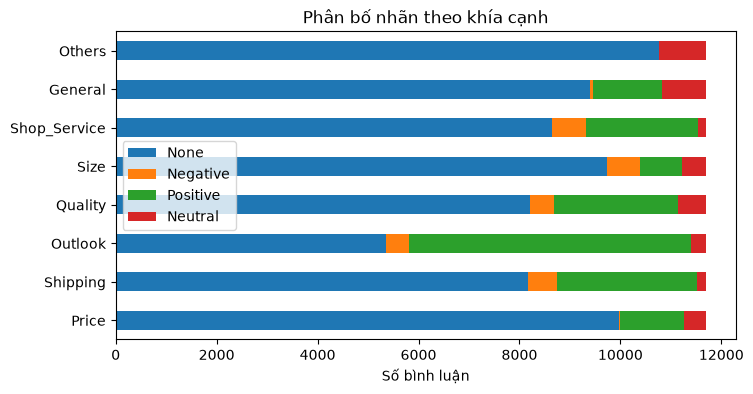

In [5]:
# Phân bố nhãn theo từng khía cạnh: phần lớn là None (khía cạnh không được nhắc đến) → dữ liệu lệch
dist = pd.DataFrame({a: df[a].value_counts().reindex(range(4), fill_value=0) for a in ASPECTS}).T
dist.columns = LABEL_NAMES
display(dist)
dist.plot(kind="barh", stacked=True, figsize=(8, 4), title="Phân bố nhãn theo khía cạnh")
plt.xlabel("Số bình luận")
plt.show()

count    8424.000000
mean       20.767331
std        20.789727
min         1.000000
25%        12.000000
50%        17.000000
75%        24.000000
max       692.000000
Name: text, dtype: float64
MAX_LEN = 47


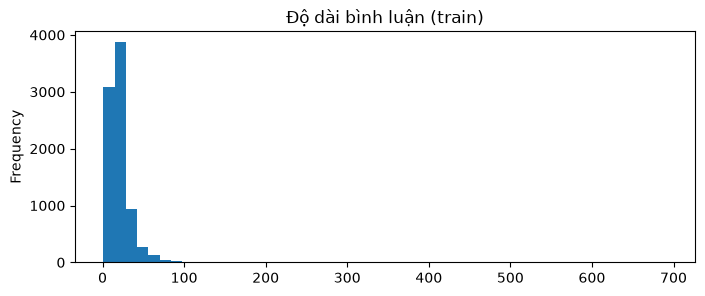

In [6]:
# Độ dài bình luận (số âm tiết) trên TẬP TRAIN — chọn max_len = phân vị 95% để cắt bớt câu quá dài
# (chỉ dùng train để val/test không ảnh hưởng tới cấu hình mô hình)
lengths = train_df["text"].str.split().str.len()
print(lengths.describe())
MAX_LEN = int(np.percentile(lengths, 95))
print("MAX_LEN =", MAX_LEN)
lengths.plot(kind="hist", bins=50, figsize=(8, 3), title="Độ dài bình luận (train)")
plt.show()

## 5. Tiền xử lý

`clean_text` (trong khối code chung) đã được áp dụng khi đọc dữ liệu: chuẩn hóa Unicode NFC, chữ thường,
bỏ URL, rút gọn chữ cái lặp (`"đẹppppp"` → `"đẹp"`), gộp khoảng trắng. Mô hình RNN tách từ theo khoảng trắng
(mức âm tiết) và xây từ điển từ tập train.

In [7]:
for s in ["Giày ĐẸPPPPP lắm, giao hàngggg nhanh!!! https://shopee.vn/abc", "Size   39 chật quá 😭"]:
    print(repr(s), "→", repr(clean_text(s)))

'Giày ĐẸPPPPP lắm, giao hàngggg nhanh!!! https://shopee.vn/abc' → 'giày đẹp lắm, giao hàng nhanh!!!'
'Size   39 chật quá 😭' → 'size 39 chật quá 😭'


## 6. Xây dựng mô hình BiLSTM

Khối code họ RNN (nguồn: `common/rnn_cells.py`, dùng chung cho NB1 và NB2):
- `build_vocab`, `encode`: từ điển và mã hóa câu thành dãy id (đệm 0 / cắt ở `max_len`).
- `RnnAbsa`: Embedding → BiLSTM 2 chiều → gộp mean + max (bỏ qua padding) → **8 đầu phân loại**, mỗi đầu 4 lớp.
- `load_rnn_predictor`: nạp mô hình đã lưu thành hàm dự đoán dùng trong UDF.

In [8]:
# === COMMON rnn_cells.py v1 ===
# Mô hình họ RNN (BiLSTM) cho ABSA — dán NGUYÊN VĂN file common/rnn_cells.py vào ô này.
import json
import os
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

try:  # khi chạy pytest
    from common.common_cells import ASPECTS, clean_text
except ImportError:  # trong notebook: đã có sẵn từ ô code chung phía trên
    pass

PAD, UNK = "<pad>", "<unk>"


def tokenize(text: str) -> list:
    """Tách từ đơn giản theo khoảng trắng sau khi làm sạch (mức âm tiết tiếng Việt)."""
    return clean_text(text).split()


def build_vocab(texts, min_freq: int = 2) -> dict:
    """Từ điển token → id. 0 = <pad>, 1 = <unk>; chỉ giữ token xuất hiện >= min_freq lần."""
    counts = Counter(tok for t in texts for tok in tokenize(t))
    vocab = {PAD: 0, UNK: 1}
    for tok, c in sorted(counts.items(), key=lambda kv: (-kv[1], kv[0])):  # sắp xếp cố định
        if c >= min_freq:
            vocab[tok] = len(vocab)
    return vocab


def encode(texts, vocab: dict, max_len: int) -> np.ndarray:
    """Chuyển văn bản → ma trận id [N, max_len] (cắt bớt nếu dài, đệm 0 nếu ngắn)."""
    out = np.zeros((len(texts), max_len), dtype=np.int64)
    for i, t in enumerate(texts):
        ids = [vocab.get(tok, 1) for tok in tokenize(t)][:max_len]
        out[i, :len(ids)] = ids
    return out


class RnnAbsa(nn.Module):
    """Embedding → BiLSTM → (mean + max pooling, bỏ qua padding) → 8 đầu phân loại 4 lớp."""

    def __init__(self, vocab_size: int, emb_dim: int = 200, hidden: int = 128,
                 n_aspects: int = 8, n_classes: int = 4, dropout: float = 0.3):
        super().__init__()
        self.n_aspects, self.n_classes = n_aspects, n_classes
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        # 8 đầu phân loại gộp thành một lớp Linear: đầu ra được reshape thành [B, 8, 4]
        self.heads = nn.Linear(4 * hidden, n_aspects * n_classes)

    def forward(self, input_ids):
        mask = (input_ids != 0).unsqueeze(-1).float()            # [B, L, 1]
        h, _ = self.lstm(self.dropout(self.embedding(input_ids)))  # [B, L, 2H]
        mean = (h * mask).sum(1) / mask.sum(1).clamp(min=1.0)
        mx = h.masked_fill(mask == 0, -1e4).max(1).values
        mx = torch.where(mask.sum(1) > 0, mx, torch.zeros_like(mx))  # câu rỗng → 0
        feats = self.dropout(torch.cat([mean, mx], dim=-1))
        return self.heads(feats).view(-1, self.n_aspects, self.n_classes)


class _RnnDataset(Dataset):
    def __init__(self, df, vocab, max_len):
        self.ids = torch.from_numpy(encode(df["text"].tolist(), vocab, max_len))
        self.labels = torch.tensor(df[ASPECTS].to_numpy(dtype=np.int64))

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        return {"input_ids": self.ids[i], "labels": self.labels[i]}


def make_rnn_loaders(train_df, val_df, vocab: dict, max_len: int, batch_size: int = 64):
    """DataLoader cho train (xáo trộn) và val; mỗi batch là {"input_ids", "labels"}."""
    return (DataLoader(_RnnDataset(train_df, vocab, max_len), batch_size=batch_size, shuffle=True),
            DataLoader(_RnnDataset(val_df, vocab, max_len), batch_size=batch_size, shuffle=False))


def save_rnn(model, vocab: dict, cfg: dict, out_dir: str) -> None:
    """Lưu trọng số (model.pt), từ điển (vocab.json) và cấu hình (config.json)."""
    os.makedirs(out_dir, exist_ok=True)
    torch.save(model.state_dict(), os.path.join(out_dir, "model.pt"))
    with open(os.path.join(out_dir, "vocab.json"), "w", encoding="utf-8") as fh:
        json.dump(vocab, fh, ensure_ascii=False)
    with open(os.path.join(out_dir, "config.json"), "w", encoding="utf-8") as fh:
        json.dump({**cfg, "vocab_size": len(vocab)}, fh, ensure_ascii=False, indent=2)


def load_rnn_predictor(model_dir: str, batch_size: int = 256):
    """Nạp mô hình đã lưu → hàm predictor(list[str]) -> np.ndarray (N, 8) nhãn 0..3."""
    with open(os.path.join(model_dir, "config.json"), encoding="utf-8") as fh:
        cfg = json.load(fh)
    with open(os.path.join(model_dir, "vocab.json"), encoding="utf-8") as fh:
        vocab = json.load(fh)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = RnnAbsa(cfg["vocab_size"], emb_dim=cfg.get("emb_dim", 200), hidden=cfg.get("hidden", 128),
                    dropout=cfg.get("dropout", 0.3))
    model.load_state_dict(torch.load(os.path.join(model_dir, "model.pt"), map_location=device))
    model.to(device).eval()
    max_len = cfg["max_len"]

    def predictor(texts) -> np.ndarray:
        preds = [np.zeros((0, len(ASPECTS)), dtype=np.int64)]
        with torch.no_grad():
            for i in range(0, len(texts), batch_size):
                ids = torch.from_numpy(encode(texts[i:i + batch_size], vocab, max_len)).to(device)
                preds.append(model(ids).argmax(-1).cpu().numpy())
        return np.concatenate(preds)

    return predictor

In [9]:
# BiLSTM huấn luyện nhanh cả trên CPU (vài phút) nên không cần cấu hình rút gọn FAST_MODE
cfg = resolve_train_config({"epochs": 10, "max_len": MAX_LEN, "batch_size": 64, "lr": 1e-3,
                            "train_frac": 1.0, "emb_dim": 200, "hidden": 128, "dropout": 0.3}, fast=False)
train_fit = train_df.sample(frac=cfg["train_frac"], random_state=SEED)

vocab = build_vocab(train_fit["text"], min_freq=2)
train_loader, val_loader = make_rnn_loaders(train_fit, val_df, vocab, cfg["max_len"], cfg["batch_size"])
model = RnnAbsa(len(vocab), emb_dim=cfg["emb_dim"], hidden=cfg["hidden"], dropout=cfg["dropout"])
print(f"Từ điển: {len(vocab)} token — số tham số: {sum(p.numel() for p in model.parameters()):,}")
model

Từ điển: 4171 token — số tham số: 1,188,536


RnnAbsa(
  (embedding): Embedding(4171, 200, padding_idx=0)
  (lstm): LSTM(200, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (heads): Linear(in_features=512, out_features=32, bias=True)
)

## 7. Huấn luyện

Loss = trung bình CrossEntropy của 8 khía cạnh. Sau mỗi epoch đo **macro-F1 trung bình 8 khía cạnh** trên tập val;
cuối cùng giữ lại trọng số của epoch tốt nhất.

Epoch 1/10 - loss 0.6117 - val macro-F1 0.4223 - 12s


Epoch 2/10 - loss 0.4035 - val macro-F1 0.5216 - 11s


Epoch 3/10 - loss 0.3444 - val macro-F1 0.5738 - 12s


Epoch 4/10 - loss 0.3127 - val macro-F1 0.5885 - 13s


Epoch 5/10 - loss 0.2883 - val macro-F1 0.6037 - 13s


Epoch 6/10 - loss 0.2710 - val macro-F1 0.6145 - 13s


Epoch 7/10 - loss 0.2580 - val macro-F1 0.6142 - 13s


Epoch 8/10 - loss 0.2415 - val macro-F1 0.6206 - 13s


Epoch 9/10 - loss 0.2319 - val macro-F1 0.6309 - 14s


Epoch 10/10 - loss 0.2189 - val macro-F1 0.6317 - 12s
Nạp lại trọng số tốt nhất: val macro-F1 = 0.6317


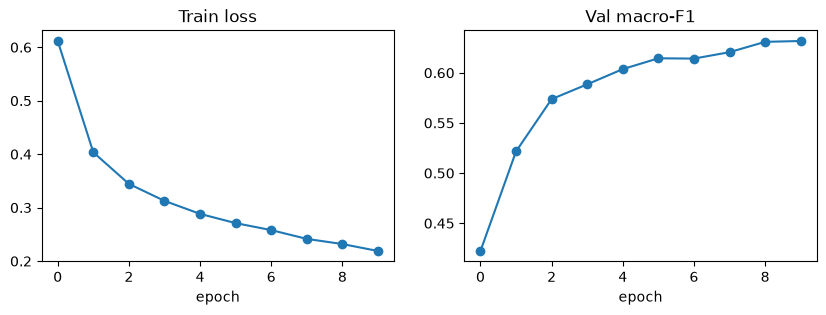

In [10]:
history = fit(model, train_loader, val_loader, epochs=cfg["epochs"], lr=cfg["lr"])

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(history["train_loss"], marker="o"); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(history["val_macro_f1"], marker="o"); ax[1].set_title("Val macro-F1"); ax[1].set_xlabel("epoch")
plt.show()

## 8. Lưu mô hình

Lưu trọng số, từ điển và cấu hình vào `./models/rnn/`.

In [11]:
MODEL_DIR = "./models/rnn"
save_rnn(model, vocab, cfg, MODEL_DIR)
print(os.listdir(MODEL_DIR))

['config.json', 'model.pt', 'vocab.json']


## 9. Đóng gói mô hình bằng `predict_batch_udf`

1. `create_spark()` dùng lại SparkSession có sẵn hoặc tạo session local.
2. `ship_model_to_spark` gửi thư mục mô hình tới mọi executor (`SparkContext.addFile`); trong UDF lấy đường dẫn
   bằng `shipped_model_path` → `SparkFiles.get` — chạy được cả khi Spark chạy trên cluster nhiều máy.
   (Riêng Jupyter trên Windows ở local mode: Hadoop cần winutils nên worker đọc thẳng bản chép của mô hình.)
3. `make_batch_udf` (nguồn: `common/udf_batch.py`) dùng `pyspark.ml.functions.predict_batch_udf`:
   - `make_predict_fn` được gọi **một lần trên mỗi worker** để nạp mô hình và trả về hàm `predict`;
   - Spark tự gom dữ liệu thành batch đúng `batch_size` dòng rồi gọi `predict`;
   - `predict` trả về dict `{khía cạnh: mảng nhãn}` ứng với kiểu struct 8 trường.

In [12]:
spark = create_spark()
shipped = ship_model_to_spark(spark, MODEL_DIR)
print(spark.version, os.path.basename(shipped))

Windows + local mode: worker đọc mô hình trực tiếp từ thư mục tạm rnn_20261115_103103_d65a61
4.3.0 rnn_20261115_103103_d65a61


In [13]:
# === COMMON udf_batch.py v1 ===
# Đóng gói mô hình bằng predict_batch_udf — dán NGUYÊN VĂN file common/udf_batch.py vào ô này.
from typing import Callable

import numpy as np
from pyspark.ml.functions import predict_batch_udf

try:  # khi chạy pytest
    from common.common_cells import ASPECTS, PRED_SCHEMA, shipped_model_path
except ImportError:  # trong notebook: đã có sẵn từ ô code chung phía trên
    pass


def make_batch_udf(load_predictor: Callable[[str], Callable], shipped_name: str, batch_size: int = 64):
    """Tạo UDF dự đoán 8 nhãn bằng pyspark.ml.functions.predict_batch_udf (Spark >= 3.4).

    - make_predict_fn() được Spark gọi một lần trên mỗi worker Python để nạp mô hình
      (shipped_model_path → SparkFiles.get, chạy được cả trên cluster) và trả về hàm predict.
    - Spark tự gom các dòng thành batch đúng `batch_size` phần tử rồi gọi predict(batch):
      batch nhỏ tốn ít bộ nhớ (GPU) hơn, batch lớn chạy nhanh hơn.
    - predict trả về dict {tên khía cạnh: mảng nhãn} ứng với kiểu trả về struct PRED_SCHEMA.
    """

    def make_predict_fn():
        predictor = load_predictor(shipped_model_path(shipped_name))

        def predict(texts: np.ndarray) -> dict:
            # Ô null có thể đến dưới dạng None hoặc NaN (float) → coi là chuỗi rỗng
            batch = [t if isinstance(t, str) else "" for t in texts]
            preds = np.asarray(predictor(batch), dtype=np.int32)
            return {a: preds[:, i] for i, a in enumerate(ASPECTS)}

        return predict

    return predict_batch_udf(make_predict_fn, return_type=PRED_SCHEMA, batch_size=batch_size)

In [14]:
rnn_udf = make_batch_udf(load_rnn_predictor, shipped, batch_size=256)

D:\ABSA-spark\.venv\Lib\site-packages\pyspark\sql\pandas\functions.py:777: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
D:\ABSA-spark\.venv\Lib\site-packages\pyspark\sql\pandas\typehints.py:60: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


## 10. Áp dụng UDF lên Spark DataFrame

Tập test được đưa vào Spark DataFrame, gọi UDF trên cột `text`, rồi tách cột struct thành 8 cột `pred_<khía cạnh>`.

In [15]:
test_sdf = to_spark_df(spark, test_df)
pred_sdf = explode_predictions(test_sdf.withColumn("pred", rnn_udf("text"))).cache()
pred_sdf.select("text", *[f"pred_{a}" for a in ASPECTS]).show(5, truncate=40)

D:\ABSA-spark\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:676: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
D:\ABSA-spark\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:953: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


+----------------------------------------+----------+-------------+------------+------------+---------+-----------------+------------+-----------+
|                                    text|pred_Price|pred_Shipping|pred_Outlook|pred_Quality|pred_Size|pred_Shop_Service|pred_General|pred_Others|
+----------------------------------------+----------+-------------+------------+------------+---------+-----------------+------------+-----------+
|giày hơi có mùi nồng, lưu ý đôi la kh...|       0.0|          0.0|         0.0|         0.0|      0.0|              0.0|         3.0|        0.0|
|hàng về đẹp lắm nha ship thân thiện đ...|       0.0|          2.0|         2.0|         0.0|      2.0|              0.0|         0.0|        0.0|
|             hàng ôk nên mua dày rất đẹp|       0.0|          0.0|         2.0|         0.0|      0.0|              0.0|         0.0|        0.0|
|bun. gti gửi oke sớ ơ đi sidbd. bởi đ...|       0.0|          0.0|         0.0|         0.0|      0.0|              0

## 11. Đánh giá bằng Spark evaluator

`evaluate_with_spark` dùng `MulticlassClassificationEvaluator` cho **từng khía cạnh**:
`accuracy`, `f1` (weighted) và macro-F1 (trung bình `fMeasureByLabel` trên các nhãn có mặt), kèm dòng trung bình.

In [16]:
result = evaluate_with_spark(pred_sdf)
display(result.round(4))

,accuracy,f1_weighted,f1_macro
Price,0.9393,0.9360,0.5738
Shipping,0.9440,0.9411,0.7083
Outlook,0.8697,0.8597,0.5780
Quality,0.8564,0.8432,0.6018
Size,0.9090,0.9091,0.6902
Shop_Service,0.8970,0.8890,0.6035
General,0.8500,0.8374,0.4877
Others,0.9697,0.9682,0.8883
Mean,0.9044,0.8980,0.6415


In [17]:
# Kiểm tra: mô hình phải tốt hơn cách đoán "None" cho mọi khía cạnh
baseline = macro_f1_mean(test_df[ASPECTS].values, np.zeros((len(test_df), 8), dtype=int))
print(f"Macro-F1 nếu luôn đoán None: {baseline:.4f} — mô hình: {result.loc['Mean', 'f1_macro']:.4f}")
assert list(result.index) == ASPECTS + ["Mean"]
assert result.loc["Mean", "f1_macro"] > baseline, "Mô hình không tốt hơn đoán toàn None"

Macro-F1 nếu luôn đoán None: 0.2426 — mô hình: 0.6415


## 12. Kết luận

Ô dưới đây tóm tắt kết quả **của chính lần chạy này** (lấy từ bảng đánh giá ở mục 11), nên luôn khớp với output.

**Nhận xét:**
- **Accuracy cao hơn hẳn macro-F1**, vì phần lớn khía cạnh trong mỗi bình luận là *None* (không được nhắc đến):
  đoán đúng None đã cho accuracy cao. Macro-F1 tính đều cho cả 4 nhãn nên phản ánh rõ hơn khả năng nhận ra
  Negative / Neutral — các nhãn ít dữ liệu và khó hơn.
- Mô hình **tốt hơn rõ rệt** so với cách luôn đoán None (dòng kiểm tra ở mục 11).
- Mô hình được đóng gói bằng **`predict_batch_udf`**, áp dụng lên Spark DataFrame và đánh giá bằng
  `MulticlassClassificationEvaluator`; mô hình được gửi tới executor bằng `addFile` / `SparkFiles`
  nên chạy được cả trên cluster nhiều máy.
- Hướng cải thiện: dùng mô hình ngữ cảnh mạnh hơn (PhoBERT — NB3/NB4) và các hàm loss xử lý mất cân bằng nhãn (NB5).

In [18]:
# Tóm tắt kết quả của lần chạy này
per_aspect = result.drop(index="Mean")
best, worst = per_aspect["f1_macro"].idxmax(), per_aspect["f1_macro"].idxmin()
print(f"Accuracy trung bình 8 khía cạnh : {result.loc['Mean', 'accuracy']:.4f}")
print(f"F1 (weighted) trung bình        : {result.loc['Mean', 'f1_weighted']:.4f}")
print(f"Macro-F1 trung bình             : {result.loc['Mean', 'f1_macro']:.4f}  (đoán toàn None: {baseline:.4f})")
print(f"Khía cạnh tốt nhất (macro-F1)   : {best} = {per_aspect.loc[best, 'f1_macro']:.4f}")
print(f"Khía cạnh kém nhất (macro-F1)   : {worst} = {per_aspect.loc[worst, 'f1_macro']:.4f}")
print()
print("Số mẫu mỗi nhãn của khía cạnh kém nhất trên tập test:",
      {n: int(c) for n, c in zip(LABEL_NAMES, np.bincount(test_df[worst], minlength=4))})

Accuracy trung bình 8 khía cạnh : 0.9044
F1 (weighted) trung bình        : 0.8980
Macro-F1 trung bình             : 0.6415  (đoán toàn None: 0.2426)
Khía cạnh tốt nhất (macro-F1)   : Others = 0.8883
Khía cạnh kém nhất (macro-F1)   : General = 0.4877

Số mẫu mỗi nhãn của khía cạnh kém nhất trên tập test: {'None': 1861, 'Negative': 11, 'Positive': 285, 'Neutral': 183}
